# Punto 2.2 — La ruta más barata por las 47 capitales de la España peninsular

**Curso:** Redes neuronales y algoritmos bioinspirados · Universidad Nacional de Colombia

Este cuaderno ejecuta todo el punto 2.2 paso a paso:

1. **Datos**: rutas reales por carretera con y sin peaje entre cada par de capitales (OpenRouteService sobre OpenStreetMap, noviembre de 2026) y tarifas de peaje de 2026.
2. **Modelo de costo**: tiempo del vendedor + combustible + peajes; en cada tramo se elige pagar el peaje o ir por la red libre.
3. **Experimento 1 (híbrido)**: colonia de hormigas (ACO) y algoritmo genético (GA) con búsqueda local, comparados con el óptimo exacto.
4. **Experimento 2 (puro)**: ACO y GA clásicos, sin búsqueda local, y la animación de cómo evoluciona la mejor solución.
5. **Sensibilidad**: ¿cambia la ruta óptima al variar el valor de la hora? ¿a partir de qué valor?

**Cómo usarlo.** Cambia los valores de la celda de **hiperparámetros** (sección 1) y ejecuta todas las celdas (*Run All*). No hace falta tocar el código de `src/`. Todos los datos están en `data/`: no se necesita internet.

Los mismos experimentos se pueden lanzar desde la terminal (`python3 src/tsp_espana.py`, `python3 src/sensibilidad.py`); el cuaderno y la terminal usan exactamente las mismas funciones.

In [1]:
# Preparación: rutas, librerías y módulos del proyecto
from pathlib import Path
import copy
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

PARTE_2 = Path.cwd()
if not (PARTE_2 / "src" / "tsp_espana.py").exists():          # por si se abre desde la raíz
    PARTE_2 = next(p for p in [Path.cwd() / "punto_2" / "parte_2", Path.cwd().parent / "parte_2"]
                   if (p / "src" / "tsp_espana.py").exists())
sys.path.insert(0, str(PARTE_2 / "src"))

import tsp_espana as te          # datos, modelo de costo, ACO/GA de la parte 1, óptimo exacto, mapas
import sensibilidad as se        # barrido del valor de la hora

pd.set_option("display.max_colwidth", 120)
datos = te.cargar_datos()
NOMBRES = datos["names"]
print(f"Carpeta del proyecto: {PARTE_2}")
print(f"Capitales: {len(NOMBRES)} · pares ordenados: {len(NOMBRES) * (len(NOMBRES) - 1)}")

Carpeta del proyecto: /home/mgtdev/documentos_estudio/ESTADISTICA/TAREAS_REDES_NEURONALES/T01_CORRECCION/punto_2/parte_2
Capitales: 47 · pares ordenados: 2162


## 1. Hiperparámetros

Todo lo que se puede cambiar está en esta celda. Después de modificarla, vuelve a ejecutar las celdas siguientes.

| Parámetro | Qué controla |
|---|---|
| `VALOR_HORA` | €/h del vendedor. Valor base: coste laboral por hora del INE, 2.º trimestre de 2026 |
| `PRECIO_COMBUSTIBLE`, `CONSUMO` | €/L de gasolina 95 y L/100 km del Toyota Corolla Hybrid 140H |
| `ACO_HIBRIDO`, `GA_HIBRIDO` | Experimento 1, con búsqueda local 2-opt + Or-opt |
| `ACO_PURO`, `GA_PURO` | Experimento 2, ACO y GA clásicos |
| `SENSIBILIDAD` | Rango y paso del barrido del valor de la hora |

Parámetros del ACO: `alpha` (peso de la feromona), `beta` (peso de la heurística $1/C_{ij}$), `rho` (evaporación), `elitismo` (refuerzo de la mejor ruta global). Parámetros del GA: `p_cruce` (cruce OX), `p_mutacion` (mutación por inversión), `p_busqueda_local` (fracción de hijos pulidos), `n_elite`, `k_torneo`.

In [2]:
# ─────────────────────────── HIPERPARÁMETROS ───────────────────────────
SEMILLA = 20261008               # misma semilla => mismo resultado
INICIO = "Madrid"                # solo cambia desde dónde se MUESTRA el ciclo

# Costos
VALOR_HORA = 26.18               # €/h  (INE, coste laboral por hora efectiva, 2T 2026)
PRECIO_COMBUSTIBLE = 1.799       # €/L  (gasolina 95, 5-oct-2026)
CONSUMO = 4.7                    # L/100 km (Toyota Corolla Hybrid 140H, WLTP)

# Experimento 1: híbrido (con búsqueda local)
ACO_HIBRIDO = dict(n_hormigas=20, iteraciones=200, alpha=1.0, beta=3.0, rho=0.1,
                   elitismo=5.0, busqueda_local=True)
GA_HIBRIDO = dict(tam_poblacion=150, generaciones=300, p_cruce=0.9, p_mutacion=0.3,
                  p_busqueda_local=0.05, n_elite=2, k_torneo=3)

# Experimento 2: puro (sin búsqueda local)
ACO_PURO = dict(ACO_HIBRIDO, n_hormigas=47, iteraciones=300, busqueda_local=False)
GA_PURO = dict(GA_HIBRIDO, generaciones=1500, p_busqueda_local=0.0)

GENERAR_GIF = True               # animación de la evolución de la mejor ruta

# Sensibilidad al valor de la hora (cada valor se resuelve con el óptimo exacto)
SENSIBILIDAD = dict(vh_min=0.0, vh_max=100.0, vh_paso=1.0)   # ~4-5 min; para ir más rápido, reduce vh_max
TOLERANCIA = 0.01                # precisión de los umbrales (€/h)
# ────────────────────────────────────────────────────────────────────────


def configurar(modo, aco, ga):
    # Configuración completa con los valores de esta celda (mismo formato que config.ini)
    cfg = copy.deepcopy(te.POR_DEFECTO)
    cfg["general"].update(semilla=SEMILLA, inicio=INICIO, generar_gif=GENERAR_GIF, modo=modo,
                          algoritmo="both", verificar_exacto=True)
    cfg["costos"].update(valor_hora=VALOR_HORA, precio_combustible=PRECIO_COMBUSTIBLE,
                         consumo_l_100km=CONSUMO)
    cfg["aco"].update(aco)
    cfg["ga"].update(ga)
    cfg["sensibilidad"].update(SENSIBILIDAD)
    te.validar_config(cfg, NOMBRES)
    return cfg


K = CONSUMO / 100 * PRECIO_COMBUSTIBLE
print(f"Combustible: {K:.4f} €/km · valor de la hora: {VALOR_HORA} €/h")

Combustible: 0.0846 €/km · valor de la hora: 26.18 €/h


## 2. Datos

Para cada par ordenado de capitales $i\to j$ hay **dos rutas reales por carretera**:

* **con peaje**: la más rápida, sin restricciones (puede usar autopistas de pago);
* **sin peaje**: la más rápida que evita las vías de peaje.

De cada una se conocen la distancia $D^r_{ij}$, el tiempo $T^r_{ij}$ y los km recorridos en cada autopista de pago. El peaje es $P^r_{ij}=\sum_a L^r_{ij,a}\,t_a$, con la tarifa $t_a$ (€/km) de 2026 de cada autopista. Las fuentes y fechas están en `data/README_DATOS.md`.

In [3]:
tarifas = pd.read_csv(PARTE_2 / "data" / "tarifas_peaje_2026.csv")
con, sin = datos["con_peaje"], datos["sin_peaje"]
fuera_diag = ~np.eye(len(NOMBRES), dtype=bool)
usa_peaje = (con["peaje"] > 0.005) & fuera_diag
retraso = (sin["horas"] - con["horas"])[usa_peaje]
print(f"Pares cuya ruta más rápida usa peaje: {usa_peaje.sum()} de {fuera_diag.sum()}")
print(f"Evitar el peaje en esos pares cuesta en mediana {60 * np.median(retraso):.0f} min "
      f"(máximo {60 * retraso.max():.0f} min)")
display(Markdown("**Tarifas de peaje de 2026 (vehículo ligero)**"))
display(tarifas[["via", "eur_km", "precio_ref_eur", "km_ref", "recorrido_ref", "fuente"]]
        .sort_values("eur_km", ascending=False).reset_index(drop=True))

Pares cuya ruta más rápida usa peaje: 957 de 2162
Evitar el peaje en esos pares cuesta en mediana 24 min (máximo 90 min)


**Tarifas de peaje de 2026 (vehículo ligero)**

,via,eur_km,precio_ref_eur,km_ref,recorrido_ref,fuente
0,C-16,0.3005,12.95,43.10,Sant Cugat-Manresa,AEA (2026) Informe precio de los peajes
1,C-32,0.2389,13.45,56.30,Castelldefels-El Vendrell,AEA (2026) Informe precio de los peajes
2,AP-46,0.2354,6.60,28.04,Alto de las Pedrizas-Málaga,AEA (2026) Informe precio de los peajes
3,AP-6,0.2256,15.70,69.60,Villalba-Adanero,AEA (2026) Informe precio de los peajes
4,AP-1,0.2176,10.04,46.13,Vitoria (Etxabarri-Ibiña)-Eibar,Bidegi (2026) tarifas vigentes desde 01-01-2026; coincide con AEA (2026)
5,AP-66,0.2083,16.20,77.76,León-Campomanes,AEA (2026) Informe precio de los peajes
6,AP-71,0.1645,6.20,37.70,León-Astorga,AEA (2026) Informe precio de los peajes
7,AP-636,0.1606,16.96,105.60,Accesos de Gipuzkoa (Bidegi),AEA (2026) Informe precio de los peajes
8,AP-8,0.1606,16.96,105.60,Bilbao-Behobia,AEA (2026); tabla oficial Bidegi/Interbiak 2026
9,AP-68 Bizkaia,0.1502,3.35,22.30,Bilbao-Ziorraga (tramo de Bizkaia),GasteizBerri (2026) AP-68: nuevos precios y peajes desde el 11 de noviembre


### Un ejemplo: A Coruña → Pontevedra

La ruta rápida va por la AP-9 (de pago); la libre tarda casi una hora más. Pagar compensa cuando el tiempo ahorrado vale más que el dinero extra:

$$V_h > V^{*}_{ij} = \frac{\big(P^{\text{con}}_{ij}-P^{\text{sin}}_{ij}\big) + k\,\big(D^{\text{con}}_{ij}-D^{\text{sin}}_{ij}\big)}{T^{\text{sin}}_{ij}-T^{\text{con}}_{ij}}$$

In [4]:
def comparar_par(origen, destino):
    i, j = NOMBRES.index(origen), NOMBRES.index(destino)
    filas = []
    for v in te.VARIANTES:
        d = datos[v]
        filas.append({"variante": v, "km": d["km"][i, j], "horas": d["horas"][i, j],
                      "peaje €": d["peaje"][i, j], "vías de peaje": d["vias"][i, j] or "—",
                      f"costo con Vh={VALOR_HORA} €": VALOR_HORA * d["horas"][i, j]
                      + K * d["km"][i, j] + d["peaje"][i, j]})
    dh = sin["horas"][i, j] - con["horas"][i, j]
    umbral = ((con["peaje"][i, j] - sin["peaje"][i, j]) + K * (con["km"][i, j] - sin["km"][i, j])) / dh
    display(pd.DataFrame(filas).round(2))
    print(f"Umbral: pagar el peaje compensa si Vh > {umbral:.2f} €/h "
          f"(ahorra {60 * dh:.0f} min y cuesta {con['peaje'][i, j]:.2f} € de peaje)")

comparar_par("A Coruña", "Pontevedra")

,variante,km,horas,peaje €,vías de peaje,costo con Vh=26.18 €
0,con_peaje,133.53,1.45,14.18,AP-9 111 km,63.50
1,sin_peaje,132.42,2.42,0.00,—,74.55


Umbral: pagar el peaje compensa si Vh > 14.75 €/h (ahorra 58 min y cuesta 14.18 € de peaje)


## 3. Modelo de costo

$$C_{ij}(V_h) = \min\Big(\underbrace{V_h T^{\text{con}}_{ij} + k D^{\text{con}}_{ij} + P^{\text{con}}_{ij}}_{\text{con peaje}},\;
\underbrace{V_h T^{\text{sin}}_{ij} + k D^{\text{sin}}_{ij} + P^{\text{sin}}_{ij}}_{\text{sin peaje}}\Big),\qquad k=\frac{\text{consumo}}{100}\cdot\text{precio}$$

El problema es un **TSP asimétrico** ($C_{ij}\neq C_{ji}$): encontrar el ciclo por las 47 capitales de menor $\sum C_{ij}$.

In [5]:
m = te.matriz_costos(datos, VALOR_HORA, PRECIO_COMBUSTIBLE, CONSUMO)
print(f"Con Vh = {VALOR_HORA} €/h conviene pagar peaje en {(m['paga_peaje'] & fuera_diag).sum()} "
      f"de {fuera_diag.sum()} pares ordenados")
print(f"Asimetría: |C_ij - C_ji| máxima = {np.abs(m['costo'] - m['costo'].T).max():.2f} €")
pd.DataFrame(m["costo"], index=NOMBRES, columns=NOMBRES).iloc[:6, :6].round(1)

Con Vh = 26.18 €/h conviene pagar peaje en 518 de 2162 pares ordenados
Asimetría: |C_ij - C_ji| máxima = 7.22 €


,Vitoria-Gasteiz,Albacete,Alacant/Alicante,Almería,Oviedo,Ávila
Vitoria-Gasteiz,0.0,206.3,257.0,316.2,131.1,132.9
Albacete,204.6,0.0,60.4,121.0,272.8,142.3
Alacant/Alicante,257.8,60.8,0.0,103.1,325.9,195.4
Almería,316.7,121.8,102.9,0.0,381.1,236.9
Oviedo,131.6,271.8,325.4,378.0,0.0,148.5
Ávila,131.0,140.5,194.1,234.3,148.4,0.0


## 4. Experimento 1 — ACO y GA con búsqueda local (híbridos)

Los algoritmos son los de la parte 1 (`punto_2/parte_1/tsp_bio.py`), aplicados a la matriz de costos en euros: la heurística del ACO pasa a ser $\eta_{ij}=1/C_{ij}$ y la aptitud del GA, el costo del ciclo. El **óptimo exacto** se calcula por programación lineal entera (formulación DFJ con eliminación de subciclos) para medir la distancia de cada algoritmo al óptimo.

In [6]:
t0 = time.time()
hib = te.ejecutar(configurar("hibrido", ACO_HIBRIDO, GA_HIBRIDO), datos, verbose=False)
print(f"Tiempo total: {time.time() - t0:.0f} s · óptimo exacto: {hib['optimo']:,.2f} €")


def tabla_resumen(r, etiqueta):
    cols = ["algoritmo", "costo_total_eur", "gap_optimo_pct", "km", "horas", "tiempo_eur",
            "combustible_eur", "peaje_eur", "tramos_con_peaje", "iteracion_mejor", "segundos"]
    t = r["resumen"][cols].copy()
    t.insert(0, "experimento", etiqueta)
    return t

display(tabla_resumen(hib, "híbrido"))

Tiempo total: 26 s · óptimo exacto: 2,543.74 €


,experimento,algoritmo,costo_total_eur,gap_optimo_pct,km,horas,tiempo_eur,combustible_eur,peaje_eur,tramos_con_peaje,iteracion_mejor,segundos
0,híbrido,ACO,2543.741,0.0,6285.733,75.806,1984.601,531.478,27.662,4,17,1.8
1,híbrido,GA,2543.741,0.0,6285.733,75.806,1984.601,531.478,27.662,4,2,13.6


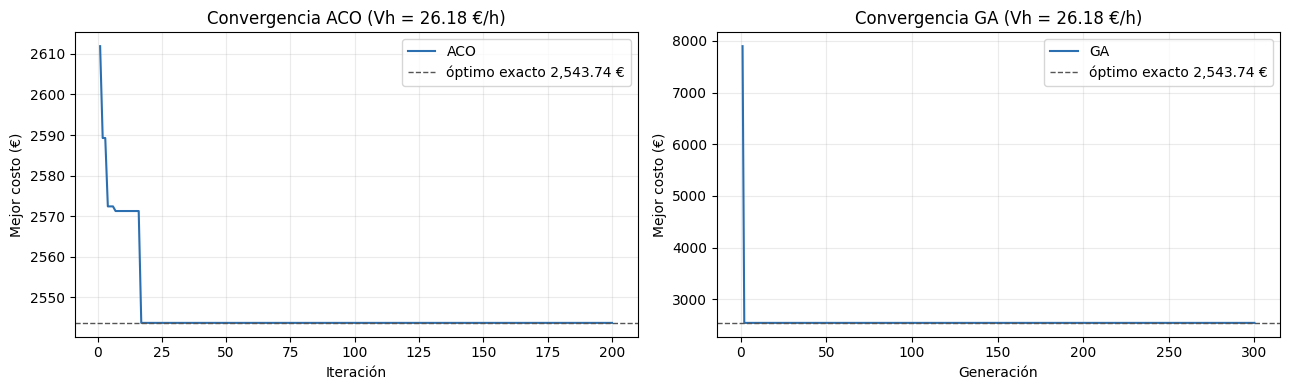

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, alg in zip(axs, ["aco", "ga"]):
    te.grafico_convergencia(hib["resultados"][alg]["historial"], alg, VALOR_HORA, hib["optimo"], ax=ax)
fig.tight_layout()
plt.show()

### Ruta óptima

Tramos en los que conviene pagar peaje (en rojo en el mapa):

,desde,hasta,vias_peaje,km,horas,peaje_eur,costo_eur
16,Vitoria-Gasteiz,Bilbao,"AP-68 Bizkaia 22 km, AP-68 Álava 15 km",65.42,0.88,3.84,32.40
19,Oviedo,A Coruña,AP-9 11 km,289.36,2.95,1.44,103.04
20,A Coruña,Pontevedra,AP-9 111 km,133.53,1.45,14.18,63.50
36,Cádiz,Málaga,AP-7 71 km,233.98,2.71,8.20,98.81


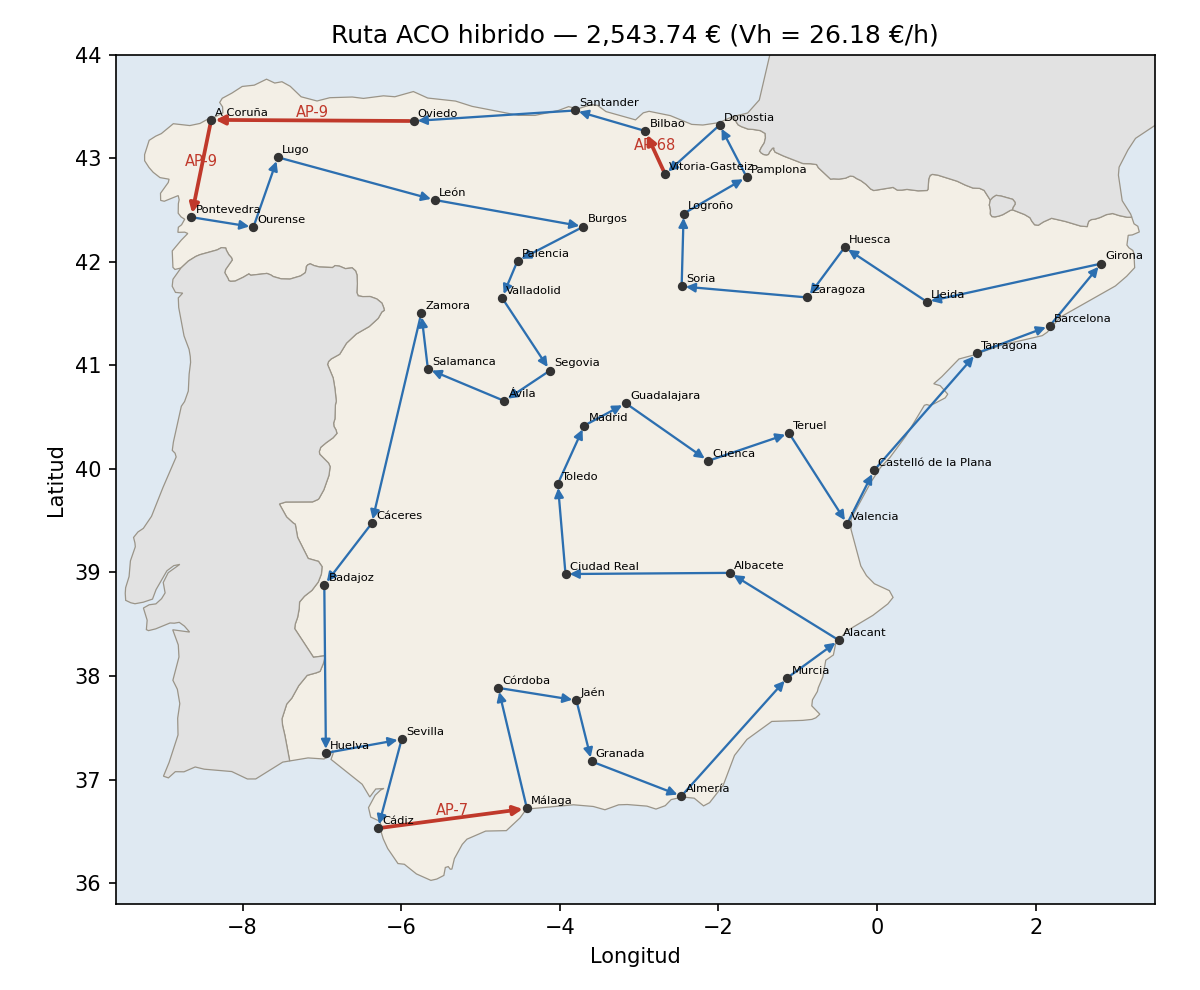

In [8]:
ruta = hib["resultados"]["aco"]["tabla"]
display(ruta[ruta["variante"] == "con peaje"][["desde", "hasta", "vias_peaje", "km", "horas",
                                               "peaje_eur", "costo_eur"]].round(2))
display(Image(filename=str(hib["carpeta"] / "mapa_ruta_aco.png"), width=720))

In [9]:
# Orden completo, tramo a tramo
hib["resultados"]["aco"]["tabla"][["orden", "desde", "hasta", "variante", "km", "horas", "tiempo_eur",
                                   "combustible_eur", "peaje_eur", "costo_eur",
                                   "costo_acumulado_eur"]].round(2)

,orden,desde,hasta,variante,km,horas,tiempo_eur,combustible_eur,peaje_eur,costo_eur,costo_acumulado_eur
0,1,Madrid,Guadalajara,libre,57.61,0.74,19.40,4.87,0.00,24.27,24.27
1,2,Guadalajara,Cuenca,libre,137.15,2.09,54.80,11.60,0.00,66.40,90.67
2,3,Cuenca,Teruel,libre,149.07,1.95,51.00,12.60,0.00,63.60,154.27
3,4,Teruel,Valencia,libre,141.51,1.68,43.89,11.97,0.00,55.85,210.13
4,5,Valencia,Castelló de la Plana/Castellón de la Plana,libre,75.53,1.05,27.42,6.39,0.00,33.80,243.93
5,6,Castelló de la Plana/Castellón de la Plana,Tarragona,libre,190.67,2.08,54.58,16.12,0.00,70.70,314.63
6,7,Tarragona,Barcelona,libre,111.91,1.44,37.62,9.46,0.00,47.08,361.71
7,8,Barcelona,Girona,libre,103.89,1.48,38.66,8.78,0.00,47.45,409.16
8,9,Girona,Lleida,libre,227.60,2.46,64.28,19.24,0.00,83.52,492.68
9,10,Lleida,Huesca,libre,117.25,1.43,37.42,9.91,0.00,47.34,540.02


## 5. Experimento 2 — ACO y GA clásicos (puros)

Sin búsqueda local se ve la capacidad propia de cada metaheurística y cómo mejora la solución a lo largo de las iteraciones/generaciones.

Tiempo total: 28 s


,experimento,algoritmo,costo_total_eur,gap_optimo_pct,km,horas,tiempo_eur,combustible_eur,peaje_eur,tramos_con_peaje,iteracion_mejor,segundos
0,híbrido,ACO,2543.741,0.000,6285.733,75.806,1984.601,531.478,27.662,4,17,1.8
1,híbrido,GA,2543.741,0.000,6285.733,75.806,1984.601,531.478,27.662,4,2,13.6
2,puro,ACO,2594.887,2.011,6489.957,77.100,2018.478,548.745,27.664,4,242,3.0
3,puro,GA,2634.456,3.566,6517.596,78.571,2056.993,551.082,26.381,4,1335,5.9


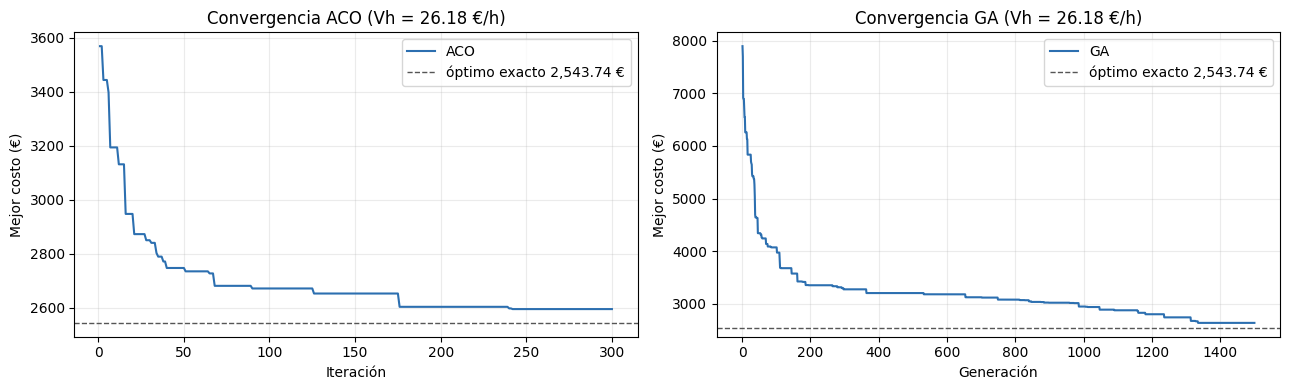

In [10]:
t0 = time.time()
pur = te.ejecutar(configurar("puro", ACO_PURO, GA_PURO), datos, verbose=False)
print(f"Tiempo total: {time.time() - t0:.0f} s")
display(pd.concat([tabla_resumen(hib, "híbrido"), tabla_resumen(pur, "puro")], ignore_index=True))

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, alg in zip(axs, ["aco", "ga"]):
    te.grafico_convergencia(pur["resultados"][alg]["historial"], alg, VALOR_HORA, pur["optimo"], ax=ax)
fig.tight_layout()
plt.show()

### Evolución de la mejor solución sobre el mapa

Un cuadro por cada mejora de la mejor ruta (rojo: tramo con peaje; azul: red libre).

**GA puro**

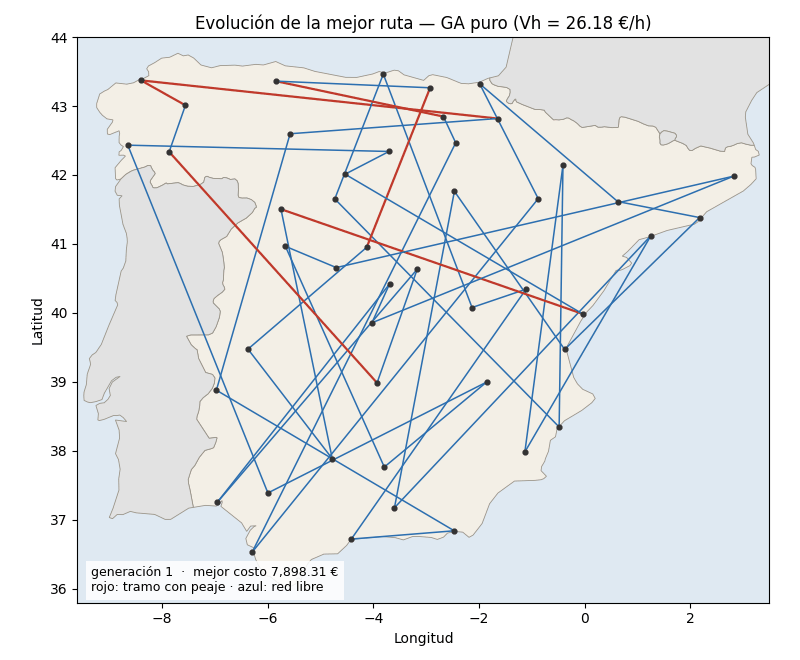

**ACO puro**

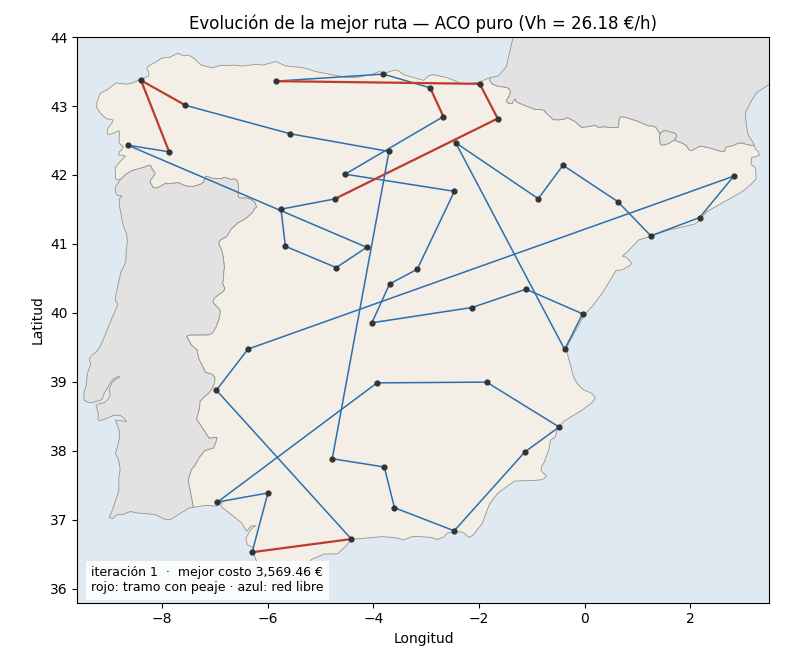

In [11]:
if GENERAR_GIF:
    for alg in ["ga", "aco"]:
        display(Markdown(f"**{alg.upper()} puro**"))
        display(Image(filename=str(pur["carpeta"] / f"evolucion_{alg}.gif"), width=640))

## 6. Sensibilidad al valor de la hora

Para cada $V_h$ de la rejilla se calcula el **óptimo exacto**, de modo que ningún cambio de ruta se debe a la aleatoriedad de una metaheurística. Entre dos valores vecinos con rutas distintas, el valor exacto del cambio se localiza por bisección. Se distinguen tres tipos de cambio:

* **orden**: cambian las conexiones entre capitales;
* **sentido**: el mismo ciclo recorrido al revés (los costos son asimétricos);
* **variante**: el orden se mantiene, pero algún tramo pasa de la red libre a la autopista de pago.

> Con un paso grande, un cambio que se deshace dentro del mismo intervalo de la rejilla puede pasar desapercibido (por ejemplo, el desvío por Andalucía entre 7,62 y 13,67 €/h no se ve con paso 25). Usa `vh_paso=1`: un paso mayor no es más rápido, porque cada intervalo contiene más cambios y la bisección los busca uno tras otro. Para una corrida más corta, reduce `vh_max`.

Barrido de 101 valores en 294 s · rutas distintas en la rejilla: 12 · cambios: 13


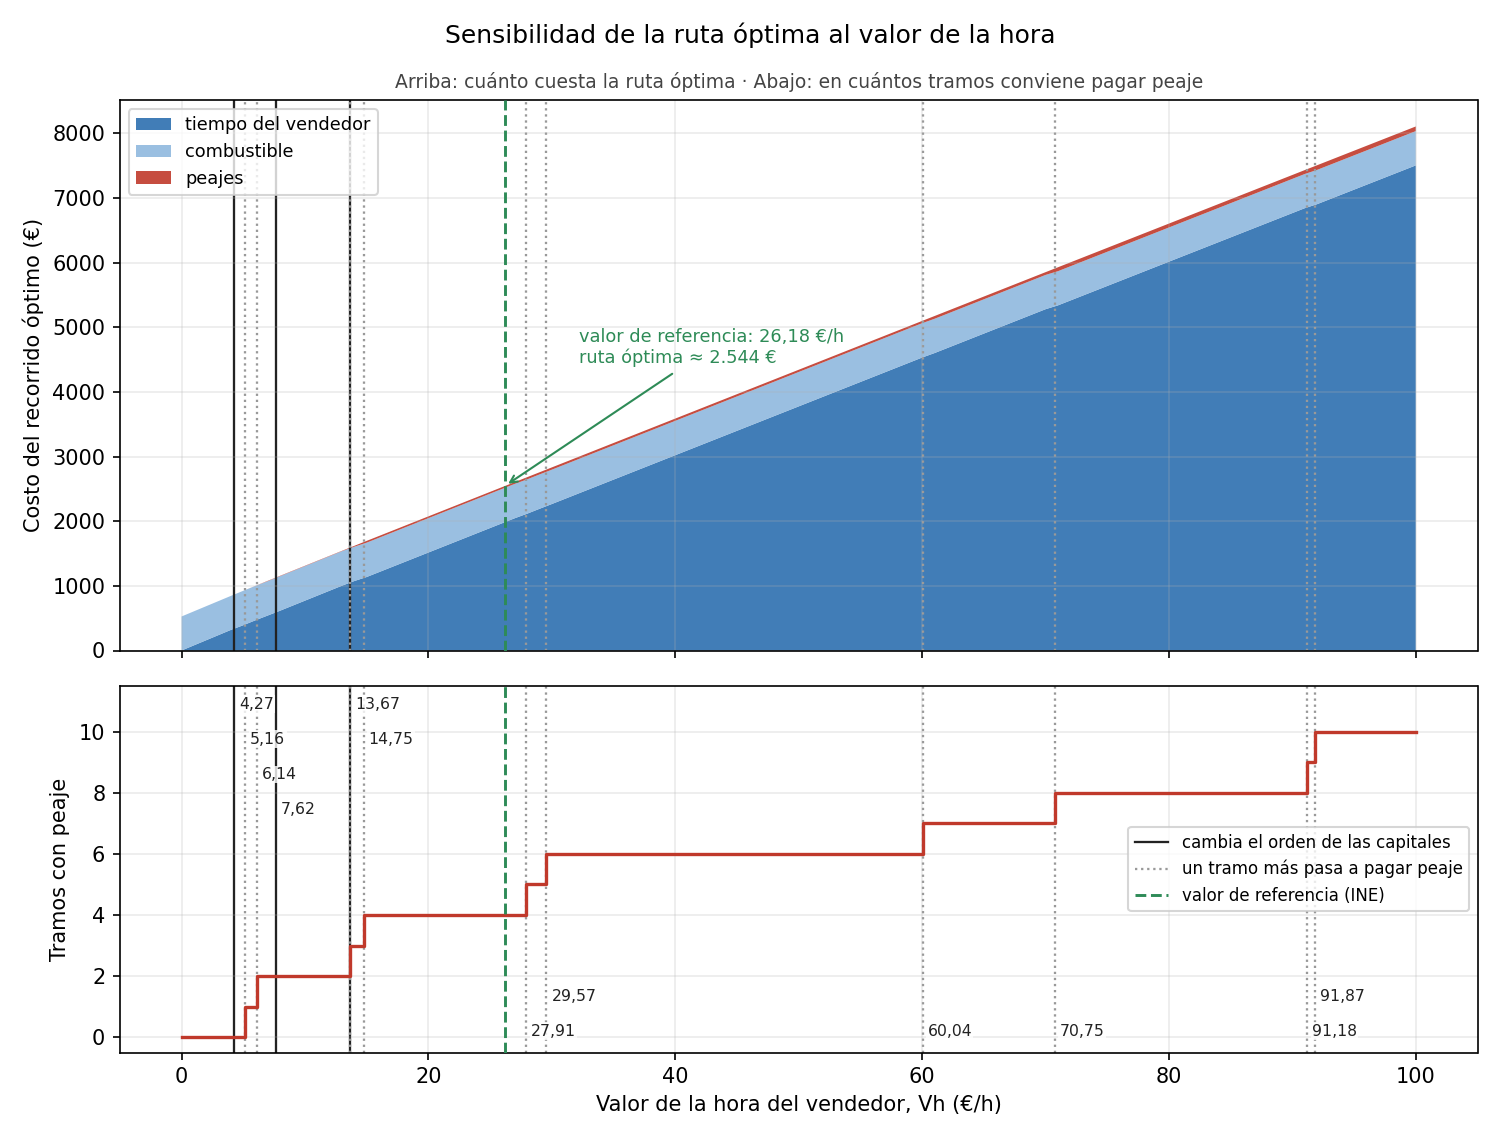

In [12]:
t0 = time.time()
sens = se.ejecutar_barrido(configurar("hibrido", ACO_HIBRIDO, GA_HIBRIDO),
                           tolerancia=TOLERANCIA, verbose=False)
print(f"Barrido de {len(sens['barrido'])} valores en {time.time() - t0:.0f} s · "
      f"rutas distintas en la rejilla: {sens['barrido']['id_ruta'].nunique()} · "
      f"cambios: {len(sens['cambios'])}")
display(Image(filename=str(sens["figura_sensibilidad"]), width=820))

In [13]:
# ¿A partir de qué valor cambia la ruta?
sens["cambios"][["vh_umbral", "tipo", "tramos_peaje_antes", "tramos_peaje_despues",
                 "km_antes", "km_despues", "cambio"]]

,vh_umbral,tipo,tramos_peaje_antes,tramos_peaje_despues,km_antes,km_despues,cambio
0,4.270,orden,0,0,6225.3,6300.9,salen: Albacete→Murcia; Alacant/Alicante→Valencia; Oviedo→León; Burgos→Soria; Córdoba→Ciudad Real; Lugo→A Coruña; Má...
1,5.160,variante,0,1,6300.9,6290.9,pasan a peaje: Oviedo→A Coruña
2,6.145,variante,1,2,6290.9,6287.6,pasan a peaje: Vitoria-Gasteiz→Bilbao
3,7.621,orden,2,2,6287.6,6324.2,salen: Cádiz→Málaga; Granada→Almería; Málaga→Córdoba | entran: Almería→Málaga; Córdoba→Cádiz; Málaga→Granada
4,13.668,orden,2,3,6324.2,6284.6,salen: Almería→Málaga; Córdoba→Cádiz; Málaga→Granada | entran: Cádiz→Málaga; Granada→Almería; Málaga→Córdoba
5,13.668,variante,2,3,6324.2,6284.6,pasan a peaje: Cádiz→Málaga
6,14.754,variante,3,4,6284.6,6285.7,pasan a peaje: A Coruña→Pontevedra
7,27.910,variante,4,5,6285.7,6287.6,pasan a peaje: Lugo→León
8,29.566,variante,5,6,6287.6,6287.5,pasan a peaje: Pamplona/Iruña→Donostia/San Sebastián
9,60.043,variante,6,7,6287.6,6272.0,pasan a peaje: Tarragona→Barcelona


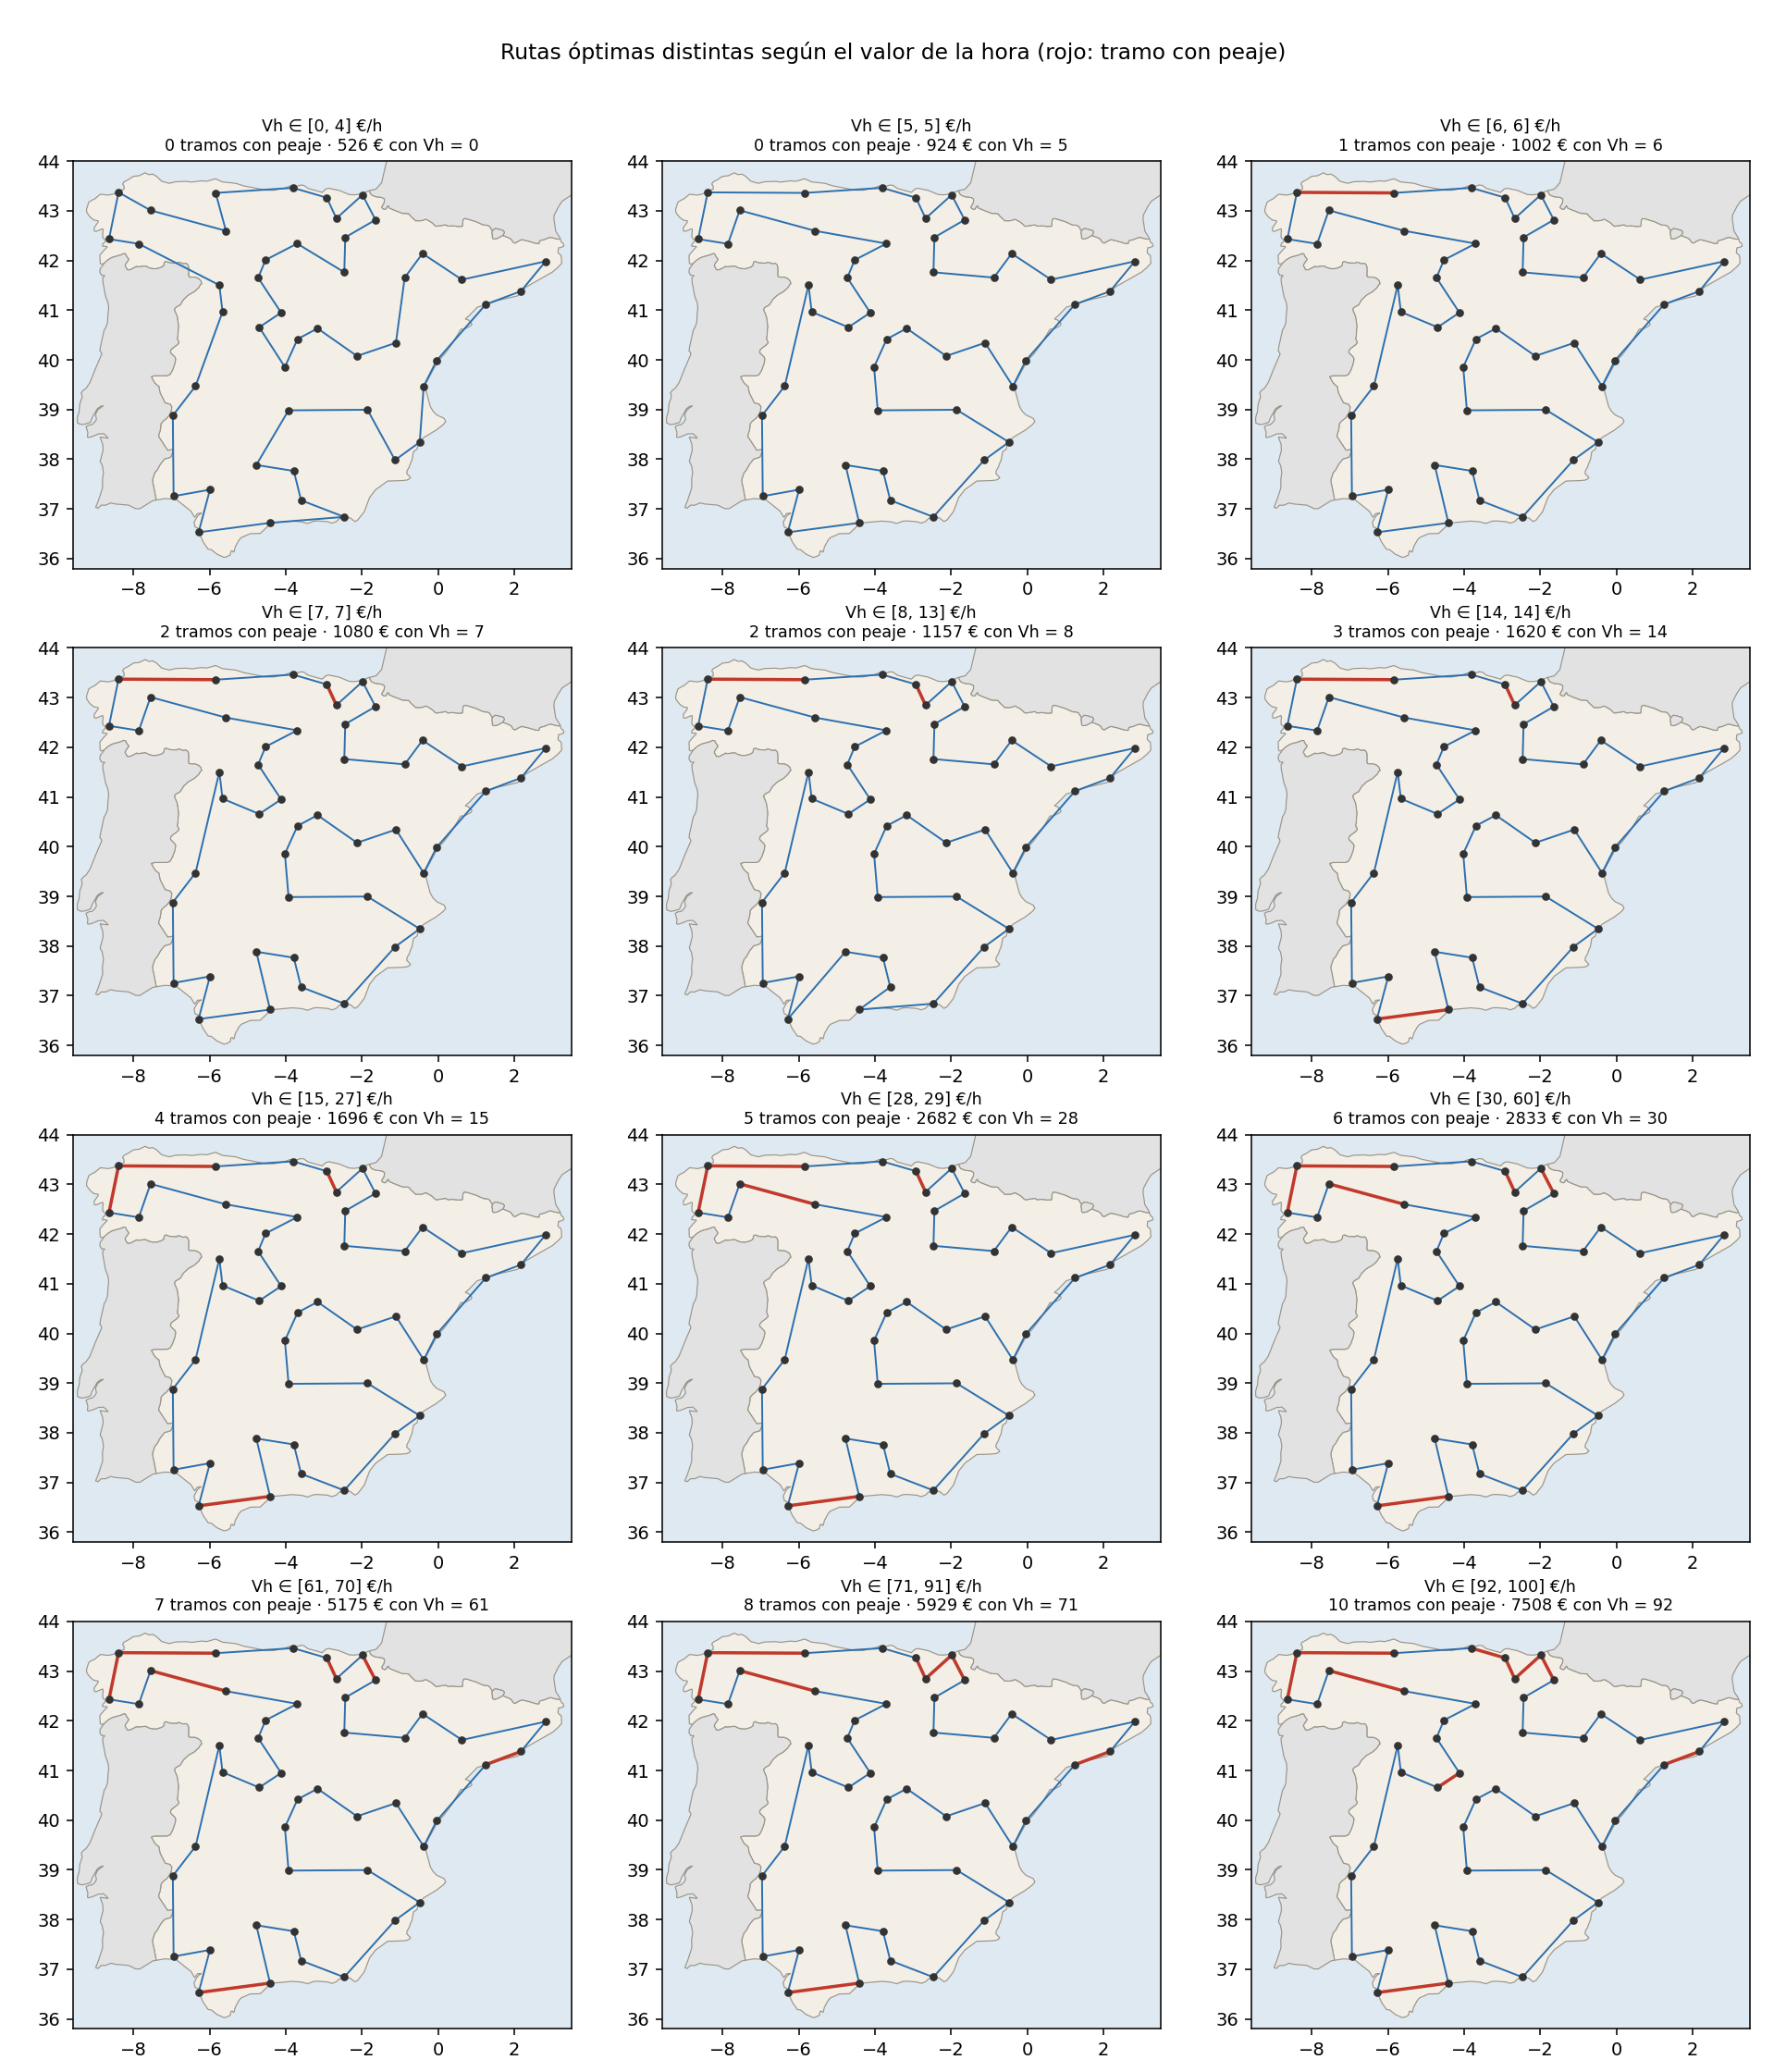

In [14]:
display(Image(filename=str(sens["figura_rutas"]), width=900))

In [15]:
# Umbral de cada tramo de la ruta óptima (Vh base), considerado por separado
ut = sens["umbrales_tramo"]
ut[ut["peaje_eur"] > 0]

,desde,hasta,vias_peaje,peaje_eur,ahorro_min,km_extra_sin_peaje,vh_umbral_eur_h,nota
20,Oviedo,A Coruña,AP-9 11 km,1.44,6.9,10.0,5.16,
17,Vitoria-Gasteiz,Bilbao,"AP-68 Bizkaia 22 km, AP-68 Álava 15 km",3.84,34.8,3.3,6.15,
37,Cádiz,Málaga,AP-7 71 km,8.20,45.2,3.0,10.54,
21,A Coruña,Pontevedra,AP-9 111 km,14.18,58.0,-1.1,14.75,
24,Lugo,León,AP-71 35 km,5.77,12.8,-1.9,27.91,
15,Pamplona/Iruña,Donostia/San Sebastián,AP-15 13 km,1.56,3.2,0.1,29.56,
7,Tarragona,Barcelona,C-32 32 km,7.72,6.4,15.7,60.04,
16,Donostia/San Sebastián,Vitoria-Gasteiz,"AP-1 74 km, AP-8 9 km",17.68,14.0,14.4,70.76,
29,Segovia,Ávila,"AP-51 23 km, AP-6 22 km, AP-61 26 km",9.46,7.0,-14.2,91.18,
18,Bilbao,Santander,AP-8 12 km,1.95,1.5,-4.6,91.87,


## 7. Prueba rápida: la ruta óptima para un valor de la hora concreto

Útil para la modificación en vivo: cambia `VH_PRUEBA`, predice qué tramos pasarán a peaje (con la tabla de umbrales de arriba) y ejecuta la celda. Calcula el óptimo exacto en unos segundos.

In [16]:
VH_PRUEBA = 60.0

r = se.resolver_vh(VH_PRUEBA, PRECIO_COMBUSTIBLE, CONSUMO)
mp = te.matriz_costos(datos, VH_PRUEBA, PRECIO_COMBUSTIBLE, CONSUMO)
t = te.tabla_ruta(list(r["ruta"]), NOMBRES, mp)
print(f"Vh = {VH_PRUEBA} €/h → costo óptimo {r['costo_eur']:,.2f} € · {r['km']:,.1f} km · "
      f"{r['horas']:.1f} h · {r['tramos_con_peaje']} tramos con peaje ({r['peaje_eur']:.2f} €)")
t[t["variante"] == "con peaje"][["desde", "hasta", "vias_peaje", "peaje_eur", "horas"]].round(2)

Vh = 60.0 €/h → costo óptimo 5,099.07 € · 6,287.6 km · 75.5 h · 6 tramos con peaje (35.00 €)


,desde,hasta,vias_peaje,peaje_eur,horas
14,Pamplona/Iruña,Donostia/San Sebastián,AP-15 13 km,1.56,1.13
16,Vitoria-Gasteiz,Bilbao,"AP-68 Bizkaia 22 km, AP-68 Álava 15 km",3.84,0.88
19,Oviedo,A Coruña,AP-9 11 km,1.44,2.95
20,A Coruña,Pontevedra,AP-9 111 km,14.18,1.45
23,Lugo,León,AP-71 35 km,5.77,2.35
36,Cádiz,Málaga,AP-7 71 km,8.20,2.71


## 8. Conclusiones

* Con $V_h = 26{,}18$ €/h, **ACO y GA híbridos encuentran el óptimo exacto** (2 543,74 €); sin búsqueda local quedan a un 2 % (ACO) y un 3,6 % (GA).
* **La ruta óptima sí cambia con el valor de la hora.** El orden de las capitales cambia con valores bajos (4,27, 7,62 y 13,67 €/h); por encima de 13,67 €/h el orden se mantiene y lo que cambia es en qué tramos compensa pagar peaje (10 umbrales entre 5,16 y 91,87 €/h).
* Con valores de la hora realistas (15–30 €/h) los peajes son ~1 % del costo: domina el tiempo de conducción.

El informe completo está en `docs/index.html` (entrada de blog).